# yada MCP

Exercises yada's MCP server — the interface a client (Goose) sees.

**Start the server first.** In VSCode run the **yada MCP server (http)**
configuration, or from the repo root:

```
YADA_MCP_TRANSPORT=streamable-http python -m mcp_server.server
```


In [5]:
%reload_ext autoreload
%autoreload 2

from utils import call_tool, list_mcp_tools, show_tool_schema, show_result


## Tools

What the server advertises. This is the whole surface a client routes over,
so it is also the tool-count budget.


In [16]:
await list_mcp_tools()


plot: Create a chart from data supplied in the request and return it as an image.
plot_report: Render a stored time series report as a chart and return it as an image.


## plot

Agent-backed: `PlotAgent` routes between bar charts and time series, so the
argument is a plain-language request rather than typed plot parameters.

It charts **what it is given**. It looks nothing up, so a result carries no
provenance — see `plot_report` for the store-backed path.


In [7]:
tool_name = "plot"
await show_tool_schema(tool_name, raw=True)


{
  "properties": {
    "request": {
      "title": "Request",
      "type": "string"
    }
  },
  "required": [
    "request"
  ],
  "title": "plotArguments",
  "type": "object"
}


{'properties': {'request': {'title': 'Request', 'type': 'string'}},
 'required': ['request'],
 'title': 'plotArguments',
 'type': 'object'}

In [8]:
await show_tool_schema(tool_name)


plot
  Create a chart from data supplied in the request and return it as an image. Handles time series (trends over time, comparisons, stacked series) and bar charts (categorical or labelled data). Send a plain-language request such as 'Plot a time series for the population of Tennessee' or 'Compare the population of Tennessee and Alabama over time'. Include the data points in the request when you have them. Note: this charts whatever it is given — it does not look anything up, and the result carries no provenance. For a chart of stored series with a report_id behind it, use plot_report instead.

  request              string   required


{'properties': {'request': {'title': 'Request', 'type': 'string'}},
 'required': ['request'],
 'title': 'plotArguments',
 'type': 'object'}

### A time series from data in the request


## Tennessee Population, 2020-2023

Tennessee's population grew steadily over this period, rising from 6.91 million in 2020 to 7.05 million in 2023.

- **Total growth:** +0.14 million (about 140,000 people) over three years, roughly 2.0% cumulative.
- **Pace of growth:** The largest single-year jump was from 2020 to 2021 (+0.07M). Annual gains then eased to +0.04M (2021-2022) and +0.03M (2022-2023), indicating a modest deceleration in year-over-year increases.
- **Overall trend:** Consistent upward movement with no declines, reflecting sustained population expansion.

[image/png] 39,017 bytes (52,024 base64 chars)


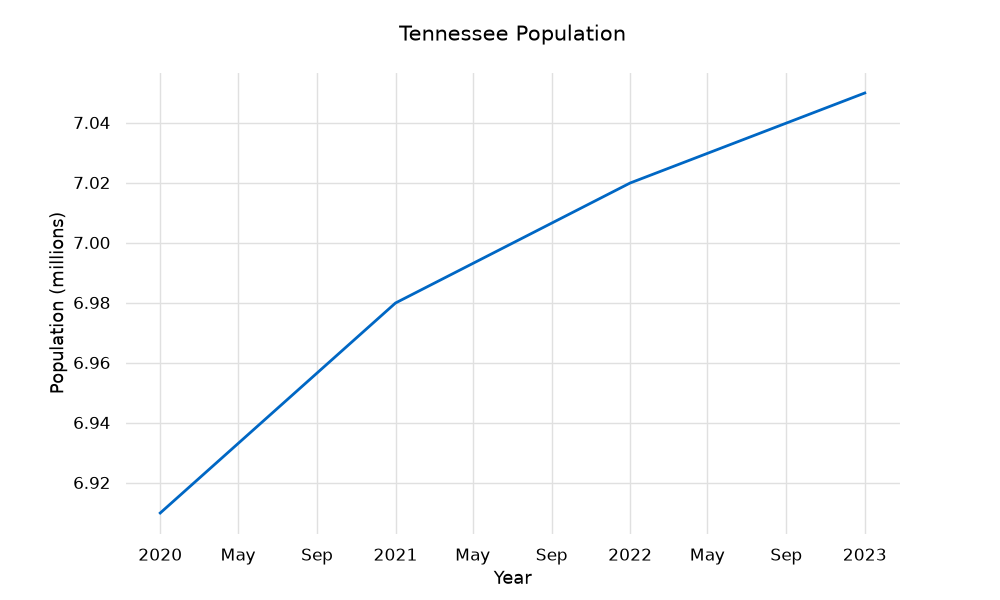

In [9]:
result = await call_tool("plot", {
    "request": "Plot a time series titled 'Tennessee population' with times "
               "2020, 2021, 2022, 2023 and values 6.91, 6.98, 7.02, 7.05.",
})
show_result(result)


### A comparison — two series on one chart


## Tennessee vs. Alabama (2020-2023)

Both series trend upward over the four-year period, but with different dynamics:

- **Tennessee** grew from 6.91 to 7.05, a gain of **0.14 (+2.03%)**, with the largest jump occurring between 2020 and 2021.
- **Alabama** grew from 5.03 to 5.11, a gain of **0.08 (+1.59%)**, with the fastest growth in the final year (2022-2023).
- **Gap:** Tennessee consistently leads Alabama by roughly 1.88 to 1.94, and that gap widened slightly over time as Tennessee grew at a modestly faster rate.

Overall, both series show steady, low-single-digit growth with Tennessee maintaining a persistent lead throughout.

[image/png] 33,511 bytes (44,684 base64 chars)


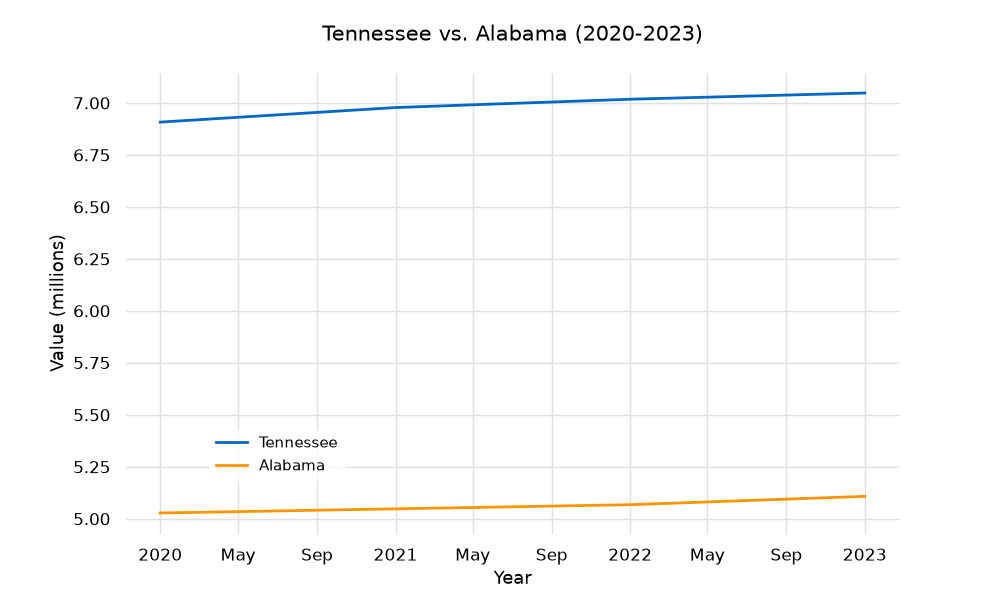

In [10]:
result = await call_tool("plot", {
    "request": "Compare two series over 2020-2023. Tennessee: 6.91, 6.98, "
               "7.02, 7.05. Alabama: 5.03, 5.05, 5.07, 5.11.",
})
show_result(result)


### A bar chart — the other branch of the router

Same tool, different sub-agent. Note the size: navi renders bars at
`dpi=300` against matplotlib's default 100 for curves, so these come back
roughly four times larger.


## 2023 Population by State

- **Tennessee** leads this group with **7.05 million** residents, more than double Mississippi's total.
- **Alabama** follows at **5.11 million**, roughly 27 percent smaller than Tennessee.
- **Kentucky** sits at **4.53 million**, closely trailing Alabama.
- **Mississippi** is the smallest at **2.94 million**, the only state in the group below 3 million.

The combined population of these four states is about **19.63 million**, with Tennessee alone accounting for roughly 36 percent of the total.

[image/png] 91,093 bytes (121,460 base64 chars)


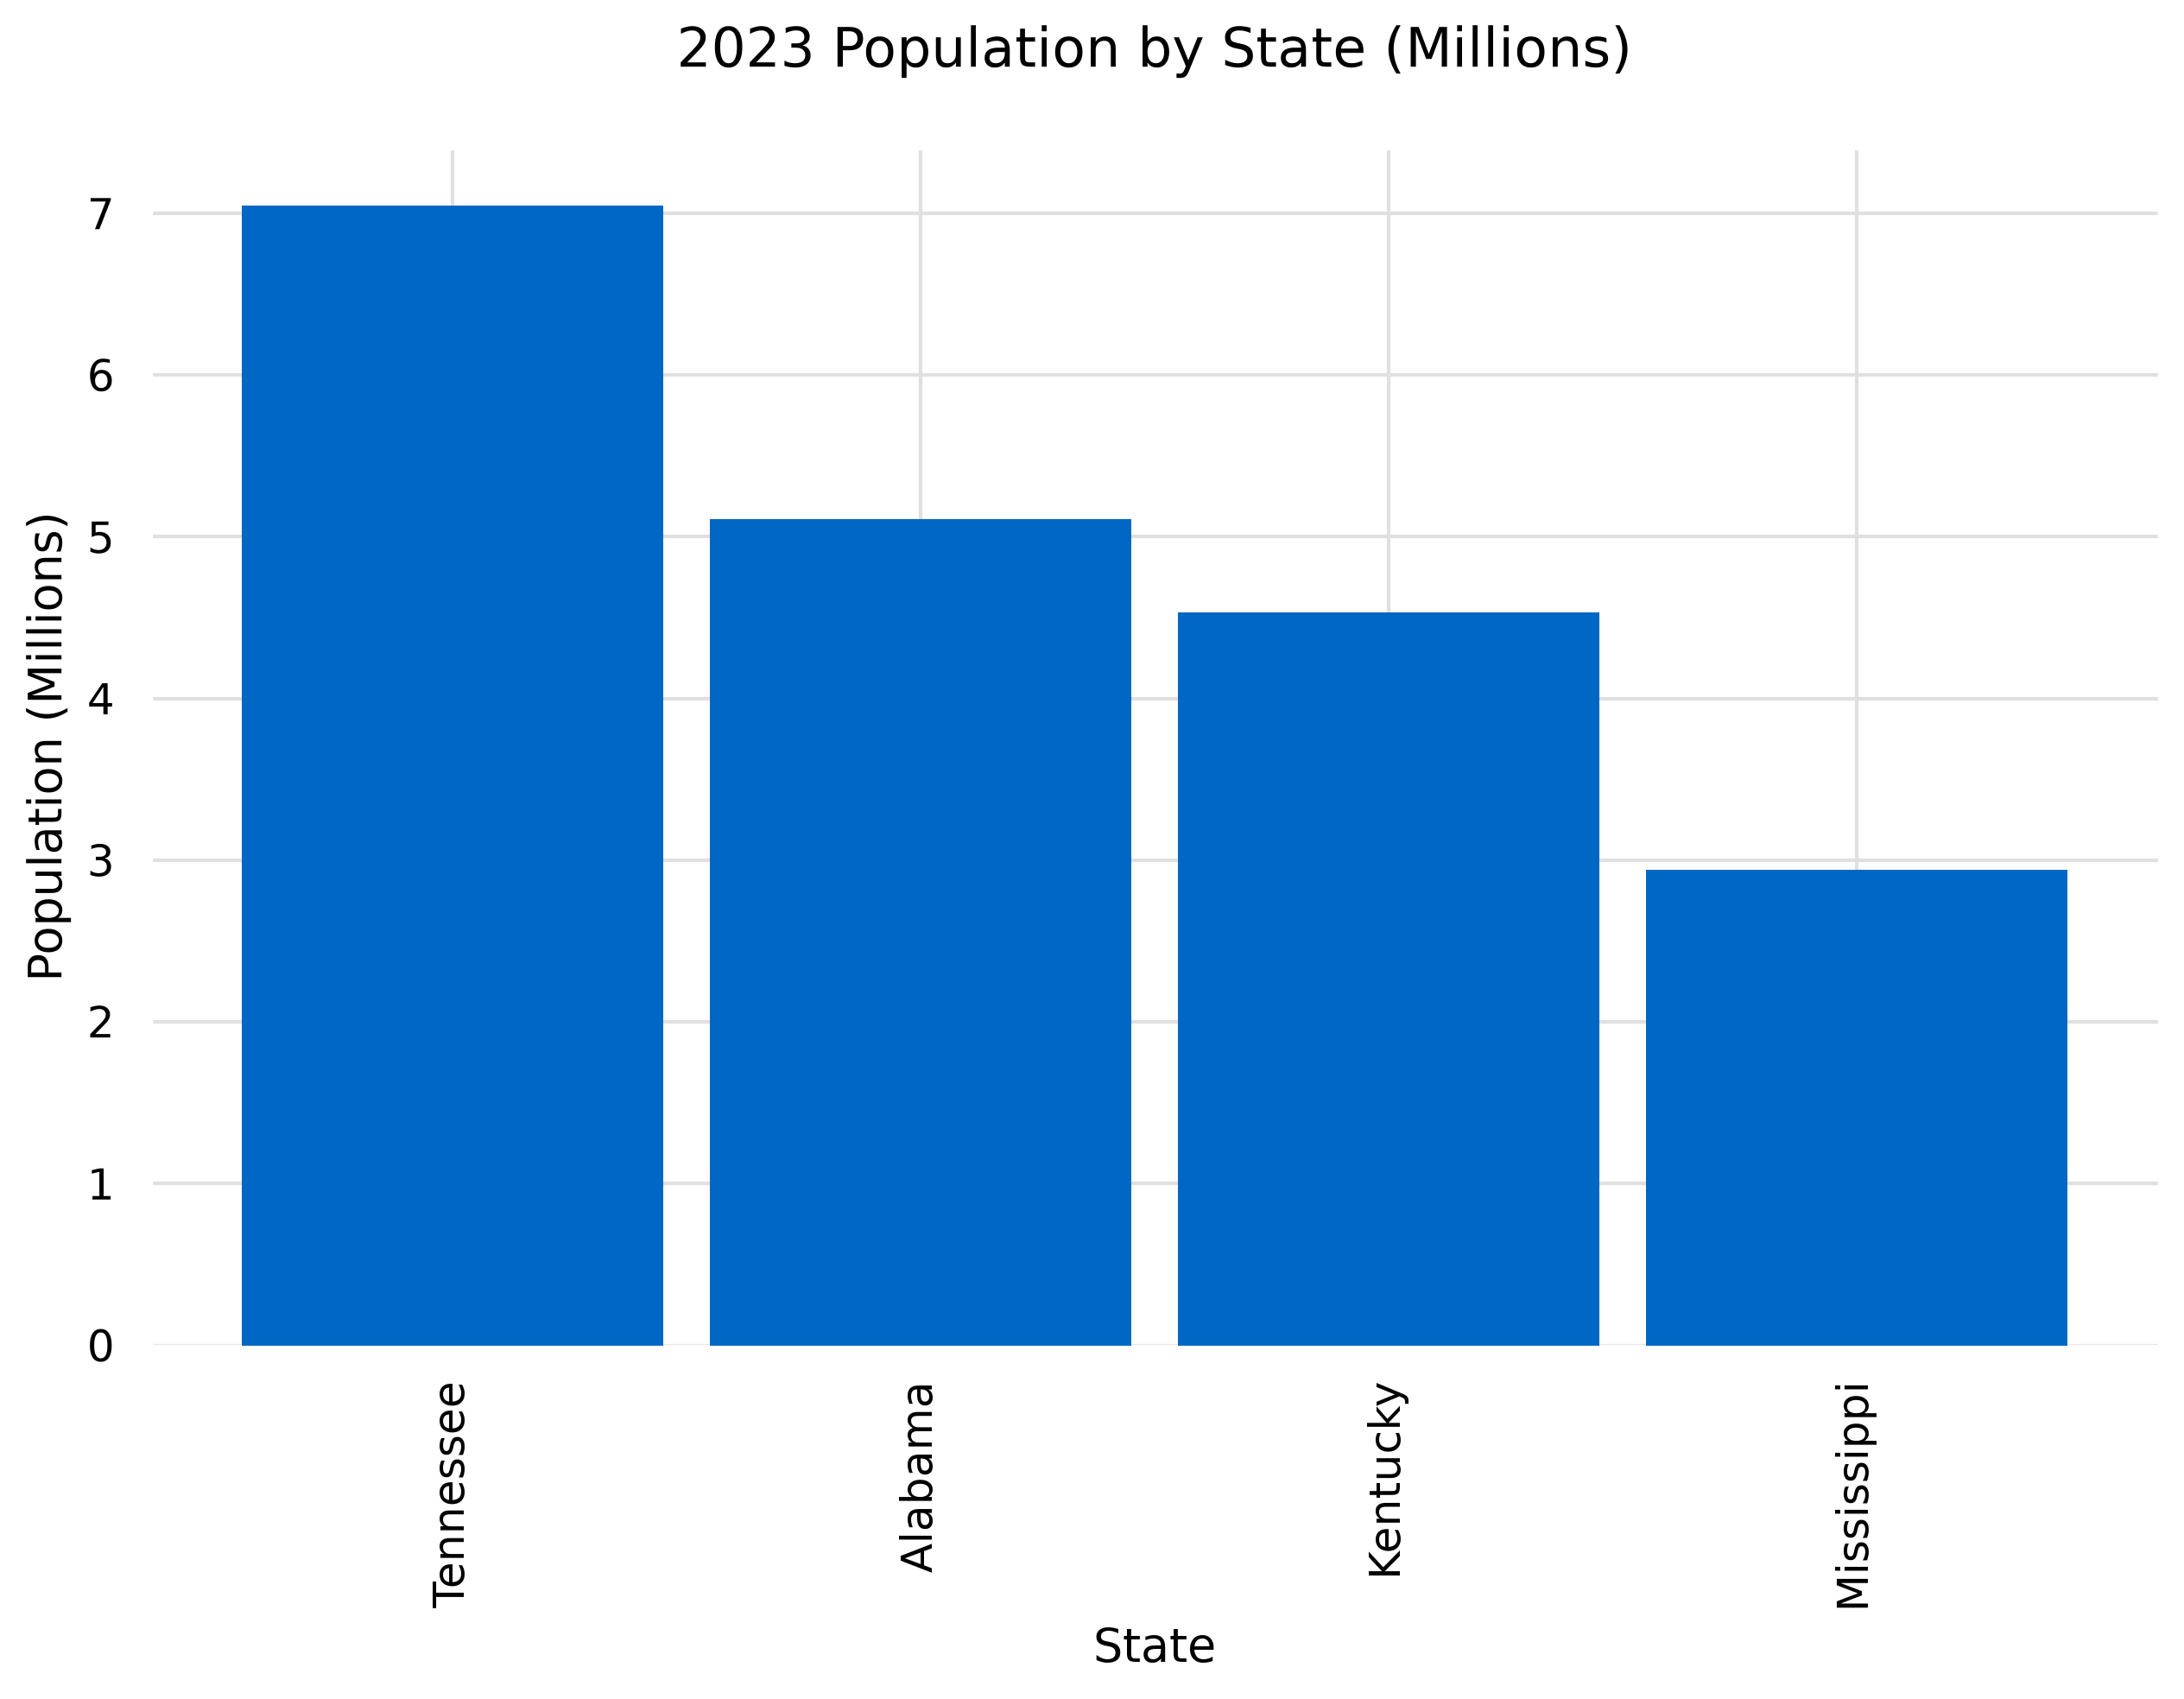

In [11]:
result = await call_tool("plot", {
    "request": "Bar chart of 2023 population in millions: Tennessee 7.05, "
               "Alabama 5.11, Kentucky 4.53, Mississippi 2.94.",
})
show_result(result)


### What a failure looks like

Worth knowing: the tool returns a text block rather than raising, so
`isError` stays `False`. A client sees a readable message, not an exception.


In [12]:
result = await call_tool("plot", {"request": "Plot nothing at all."})
show_result(result)


I can't create a plot with no data or specifications. To help you visualize something, please provide:

- **Data**: What values or measurements do you want to plot?
- **Chart type**: Do you want a bar chart, time series, or another type?
- **Context**: What are you comparing or tracking?

Once you share these details, I'll generate the chart for you.

## plot_report

Deterministic: no LLM, no agent. Takes a report id (or a title substring),
loads that report's series from the cache and renders them.

This is the **id-passing** path — the model carries an id and never holds the
values, so the numbers on the chart are always the stored ones.


In [13]:
tool_name = "plot_report"
await show_tool_schema(tool_name, raw=True)


{
  "properties": {
    "report_id_or_title": {
      "title": "Report Id Or Title",
      "type": "string"
    }
  },
  "required": [
    "report_id_or_title"
  ],
  "title": "plot_reportArguments",
  "type": "object"
}


{'properties': {'report_id_or_title': {'title': 'Report Id Or Title',
   'type': 'string'}},
 'required': ['report_id_or_title'],
 'title': 'plot_reportArguments',
 'type': 'object'}

In [14]:
await show_tool_schema(tool_name)


plot_report
  Render a stored time series report as a chart and return it as an image. Takes a report UUID, or a case-insensitive substring of the report title. The chart is drawn from the series cached under that report — it is never built from values supplied in the request, so the returned numbers are always the stored ones. Plot type and axis scale are chosen automatically from the series count and their units. Use this whenever the user asks to see, plot, chart or visualise a report they have already created.

  report_id_or_title   string   required


{'properties': {'report_id_or_title': {'title': 'Report Id Or Title',
   'type': 'string'}},
 'required': ['report_id_or_title'],
 'title': 'plot_reportArguments',
 'type': 'object'}

### Plotting a stored report

Needs a report in `yada_dev`. Creating one requires document search and a
series fetch, which are not exposed yet — so until then this returns the
not-found message below.


In [15]:
result = await call_tool("plot_report", {"report_id_or_title": "unemployment"})
show_result(result)


Could not plot report: No report found matching 'unemployment'.